# HW7: Inverse modeling via ensemble smoothing (ES-MDA)

In [2]:
using DelimitedFiles
using Statistics
using LinearAlgebra
using SparseArrays
using Random
using DataFrames
using CairoMakie

Same domain and flow BCs as HW6: no-flow top/bottom, $u_{in} = 0.1$ cm/min on the left, $h_R = 9$ m on the right. Observation error $\sigma_h = 0.02$ m, $n_{Update} = 5$.

In [3]:
# physical properties
ρ = 1000 # water density [kg/m^3]
μ = 1.0e-3 # dynamic viscosity [Pa s]
g = 9.81 # gravitational acceleration [m/s^2]

# model domain
Lx = 100 # domain length in x [m]
Ly = 50 # domain length in y [m]
nx = 100 # number of cells in x
ny = 50 # number of cells in y
dx = Lx / nx # = 1 m
dy = Ly / ny # = 1 m

# boundary conditions (HW6)
uin = 0.1 / 100 / 60 # left boundary inflow [m/s] == 0.1 cm/min (Neumann)
hR = 9 # right boundary head [m] (Dirichlet)

# data assimilation
hSig = 0.02 # observation-error std [m]
nUpdate = 5 # number of ES-MDA steps
seed = 85 # fixed random seed

85

### Forward model
Port of `forwardModel.m`: steady-state TPFA flow, returns the head field.

In [4]:
### Steady-state 2-D flow (TPFA)
# Neumann inflow uin on the left, Dirichlet head hR on the right, no-flow top and bottom.
# Kmat is ny*nx hydraulic conductivity [m/s]. Returns the ny*nx head field [m].
function forward_model(Kmat, dx, dy, uin, hR)
    ny, nx = size(Kmat)
    nc = nx * ny

    # face conductivities, harmonic mean between neighbouring cells
    Kfx = 2 ./ (1 ./ Kmat[:, 1:(nx - 1)] .+ 1 ./ Kmat[:, 2:nx])
    Kfy = 2 ./ (1 ./ Kmat[1:(ny - 1), :] .+ 1 ./ Kmat[2:ny, :])

    TLmat = [zeros(ny, 1) (dy/dx) .* Kfx] # left boundary: Neumann, enters b
    TRmat = [(dy/dx) .* Kfx (2*dy/dx) .* Kmat[:, nx]] # right boundary: hR half a cell away
    TUmat = [zeros(1, nx); (dx/dy) .* Kfy] # top: no-flow
    TDmat = [(dx/dy) .* Kfy; zeros(1, nx)] # bottom: no-flow

    TL, TR, TU, TD = vec(TLmat), vec(TRmat), vec(TUmat), vec(TDmat)
    TC = TL .+ TR .+ TU .+ TD
    Tmat = spdiagm(
        0 => TC,
        -ny => -TL[(ny + 1):nc],
        -1 => -TU[2:nc],
        1 => -TD[1:(nc - 1)],
        ny => -TR[1:(nc - ny)],
    )

    bmat = zeros(ny, nx)
    bmat[:, 1] .= uin * dy # left boundary: specified inflow
    bmat[:, nx] .= TRmat[:, nx] .* hR # right boundary: specified head
    return reshape(Tmat \ vec(bmat), ny, nx)
end

# heads [m] at all cells for one log10(k) field x (length nc)
heads(x) = vec(forward_model(ρ*g/μ .* 10 .^ reshape(x, ny, nx), dx, dy, uin, hR))
# heads of every ensemble member, nc × Ne (one member per column)
function ensemble_heads(xEns)
    reduce(hcat, map(heads, eachcol(xEns)))
end

rmse(a, b) = sqrt(mean((a .- b) .^ 2))
reduction(r) = 100 .* (1 .- r ./ r[1]) # RMSE reduction [%] relative to step 0

reduction (generic function with 1 method)

### Monitoring network
50 cells (5 rows by 10 columns)

In [5]:
xInd = round.(Int, range(10, nx - 9, length = 10)) # column index
yInd = round.(Int, range(5, ny - 4, length = 5)) # row index
obsInd = vec(LinearIndices((ny, nx))[yInd, xInd]) # linear (column-major) cell index
Nd = length(obsInd)

50

### ES-MDA
Port of `ensembleSmoothing.m`, repeated $n_{Update}$ times with $\alpha_i = n_{Update}$:

$$\mathbf{K}_i = \mathbf{C}_{xy,i}\left(\mathbf{C}_{yy,i} + \alpha_i \mathbf{C}_d\right)^{-1}, \quad
\mathbf{x}_j^{i+1} = \mathbf{x}_j^i + \mathbf{K}_i\left(\mathbf{d} + \boldsymbol{\epsilon}_{j,i} - \mathbf{y}_j^i\right), \quad
\boldsymbol{\epsilon}_{j,i} \sim \mathcal{N}(\mathbf{0}, \alpha_i \mathbf{C}_d)$$

The true field only makes the synthetic data and the RMSEs so it never enters the update.

In [6]:
### ES-MDA on x = log10(k)
# xTrue: true log10(k) (nc), xPrior: prior log10(k) ensemble (nc x Ne).
# Returns RMSE_k and RMSE_h at steps 0..nUpdate and the ensemble-mean log10(k) at every step.
function es_mda(xTrue, xPrior, nUpdate, seed)
    rng = Xoshiro(seed)
    Ne = size(xPrior, 2)
    α = nUpdate # equal inflation, sum(1/α) = 1

    # run the forward using true field at all 50 locations, 
    # and generate 1 fixed synthetic observation vector d = h_true,obs + ϵ
    hTrue = heads(xTrue)
    obs = hTrue[obsInd] .+ hSig .* randn(rng, Nd)

    x = copy(xPrior)
    rmse_k, rmse_h, xMean_ls = Float64[], Float64[], Vector{Float64}[]
    for i in 0:nUpdate
        # 2. & 4. run the forward model with the current ensemble
        H = ensemble_heads(x)
        xMean = vec(mean(x, dims = 2)) # mean of log10(k), not log10 of mean k
        push!(xMean_ls, xMean)
        push!(rmse_k, rmse(xMean, xTrue))
        push!(rmse_h, rmse(vec(mean(H, dims = 2)), hTrue))
        if i == nUpdate
            break
        end

        # at assimilation step i update each member using Ki xj i+1
        # α Cd
        y = H[obsInd, :]
        Ax = x .- mean(x, dims = 2)
        Ay = y .- mean(y, dims = 2)
        Cxy = Ax * Ay' / (Ne - 1)
        Cyy = Ay * Ay' / (Ne - 1)
        K_gain = Cxy / (Cyy + α * hSig^2 * I)
        ϵ = sqrt(α) * hSig .* randn(rng, Nd, Ne) # multiply the perturbation std by sqrt(α)
        x = x .+ K_gain * (obs .+ ϵ .- y)
    end
    return (; rmse_k, rmse_h, xMean_ls)
end

# RMSEs and reduction rates at every step
step_table(r) = DataFrame(
    "step" => 0:(length(r.rmse_k) - 1),
    "RMSE_k (log10 m^2)" => round.(r.rmse_k, digits = 4),
    "RMSE_h (m)" => round.(r.rmse_h, digits = 4),
    "RMSE_k reduction (%)" => round.(reduction(r.rmse_k), digits = 1),
    "RMSE_h reduction (%)" => round.(reduction(r.rmse_h), digits = 1),
)

step_table (generic function with 1 method)

### Data

In [7]:
## true field and prior ensemble, permeability [m^2]
kmat_true = readdlm("data/permeability_field.csv", ',', Float64) # ny × nx
kmat_ensemble = readdlm("data/permeability_ensemble.csv", ',', Float64) # nc × Ne, one member per column
xTrue = vec(log10.(kmat_true)) # update log10(k), not k
xPrior = log10.(kmat_ensemble)
Ne = size(xPrior, 2) # = 300

300

In [8]:
set_theme!(theme_latexfonts()) ## plot settings
update_theme!(fontsize = 20)

steps = 0:nUpdate
X = range(dx / 2, step = dx, length = nx) # cell-center coordinates [m]
Ycoord = range(dy / 2, step = dy, length = ny) # y = 0 on top, as in Figure 1
obsXY = vec([Point2f(X[j], Ycoord[i]) for i in yInd, j in xInd]) # monitoring locations
klabel = L"\log_{10}k\ (\mathrm{m^2})"

function kmap!(pos, x, title, crange)
    ax = Axis(pos, title = title, titlefont = :regular, xlabel = "x (m)", ylabel = "y (m)", yreversed = true,
        aspect = DataAspect(), limits = (0, Lx, 0, Ly))
    heatmap!(ax, X, Ycoord, reshape(x, ny, nx)', colorrange = crange, colormap = :viridis)
    return ax
end

kmap! (generic function with 1 method)

**Problem 1**
Perform ES-MDA with $n_{Update} = 5$ on the original fields. 
Evaluate  the  initial ensemble (Step 0) and the updated ensemble after each of assimilation steps  𝑖 =[1,2,3,4,5]. 

In [9]:
p1 = es_mda(xTrue, xPrior, nUpdate, seed)
step_table(p1) # Table 1.

Row,step,RMSE_k (log10 m^2),RMSE_h (m),RMSE_k reduction (%),RMSE_h reduction (%)
,Int64,Float64,Float64,Float64,Float64
1,0,1.0055,0.7048,0.0,0.0
2,1,0.7197,0.4443,28.4,37.0
3,2,0.6763,0.4904,32.7,30.4
4,3,0.658,0.3338,34.6,52.6
5,4,0.657,0.3447,34.7,51.1
6,5,0.6608,0.3524,34.3,50.0


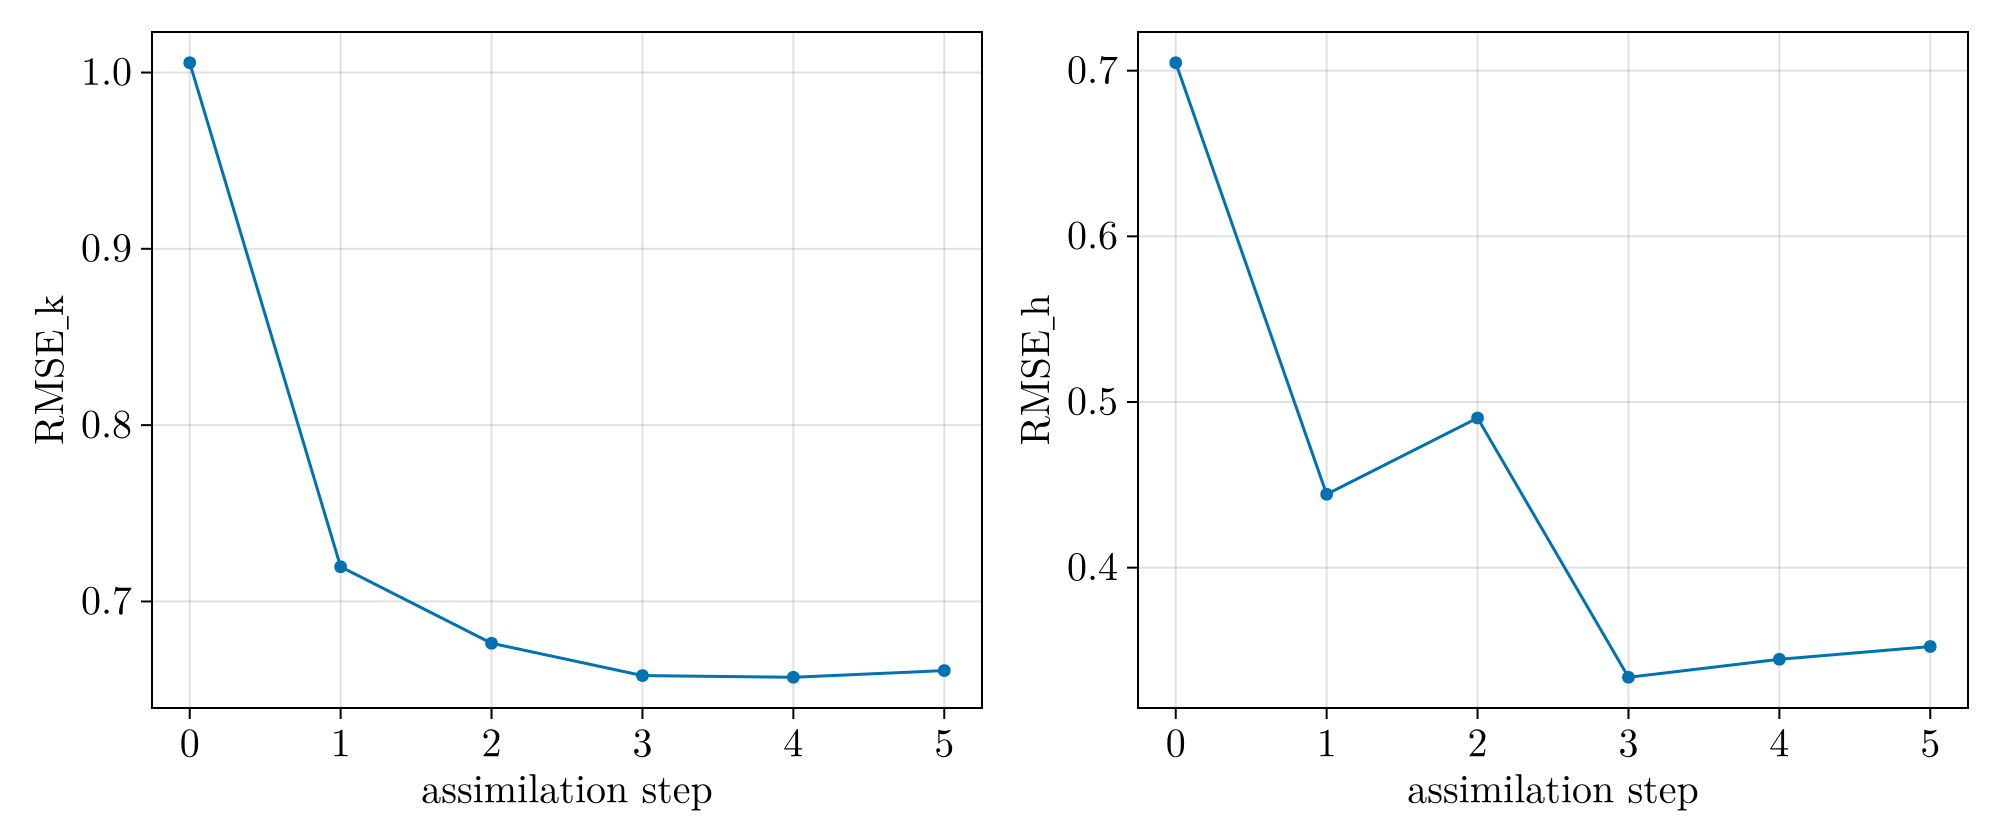

In [10]:
# RMSE vs assimilation step
fig1 = Figure(size = (1000, 420))
ax_k = Axis(fig1[1, 1], xticks = steps, xlabel = "assimilation step", ylabel = "RMSE_k")
ax_h = Axis(fig1[1, 2], xticks = steps, xlabel = "assimilation step", ylabel = "RMSE_h")
scatterlines!(ax_k, steps, p1.rmse_k)
scatterlines!(ax_h, steps, p1.rmse_h)
fig1

In [11]:
save("figures/hw7-p1-rmse.png", fig1)

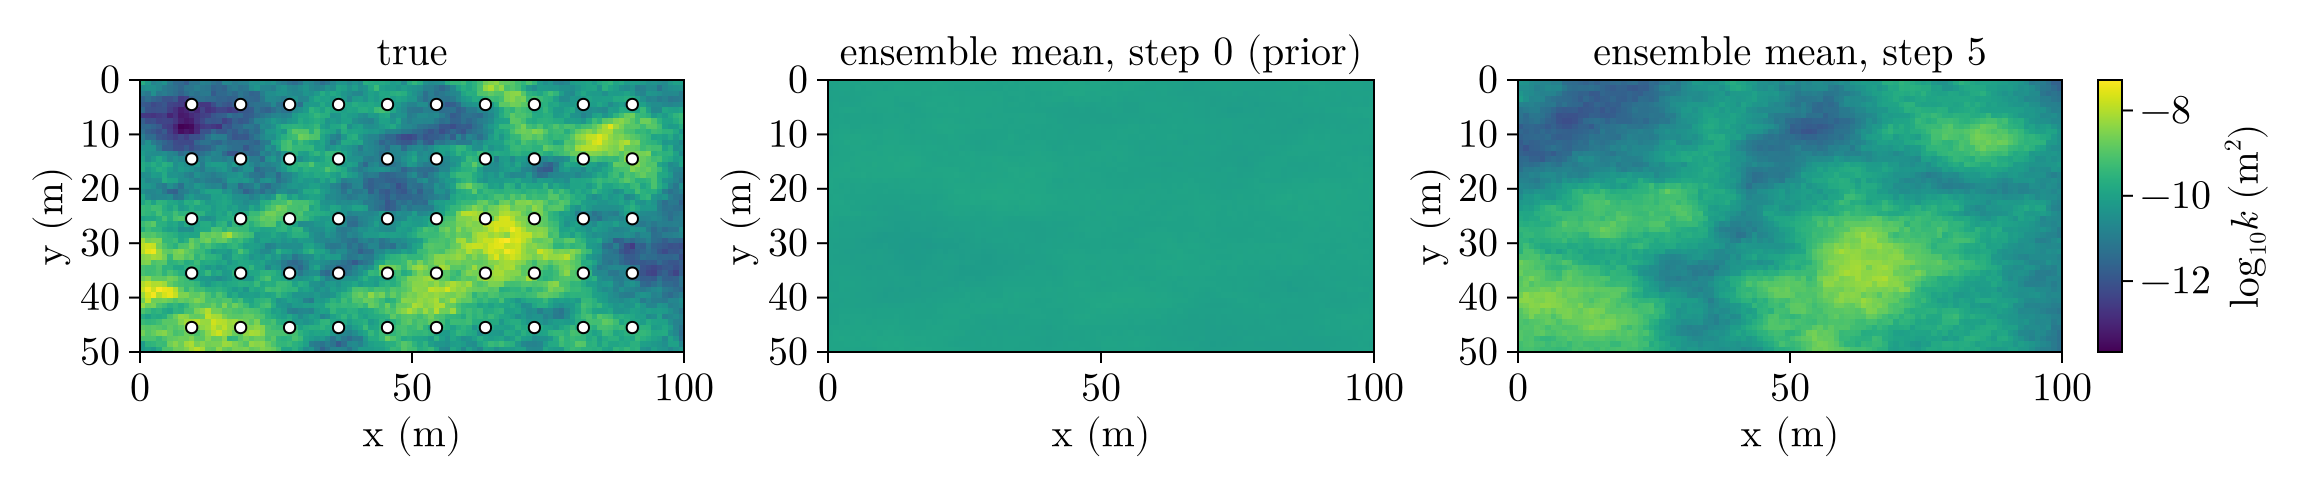

In [12]:
# true vs ensemble-mean log10(k) at steps 0 and 5, same color scale
crange = extrema(xTrue)
fig2 = Figure(size = (1150,800))
ax = kmap!(fig2[1, 1], xTrue, "true", crange)
scatter!(ax, obsXY, color = :white, strokecolor = :black, strokewidth = 1, markersize = 8)
kmap!(fig2[1, 2], p1.xMean_ls[1], "ensemble mean, step 0 (prior)", crange)
kmap!(fig2[1, 3], p1.xMean_ls[end], "ensemble mean, step $nUpdate", crange)
Colorbar(fig2[1, 4], limits = crange, colormap = :viridis, label = klabel)
rowsize!(fig2.layout, 1, Aspect(1, 0.5)) # colorbar as tall as the maps
resize_to_layout!(fig2) # trim empty space
fig2

In [13]:
save("figures/hw7-p1-maps.png", fig2)

- $\mathrm{RMSE}_k$ drops from 1.0055 (prior) to 0.7003 after step 1 (Table 1, Fig1 left), then drop to near 0.65 (Table 1, Fig1 left). Most of the gain is within step 1.
- $\mathrm{RMSE}_h$ drops from 0.705 m to 0.335 m by step 5 (Table 1, Fig 1 right). It falls to 0.422 m at step 1 and 0.344 m at step 3, then barely moves.

No, neither curve is monotonic. $\mathrm{RMSE}_h$ goes back up at step 2. $\mathrm{RMSE}_k$ goes up a bit at step 3 (0.653 to 0.659) and step 5 (0.646 to 0.654), and the best is step 4 (35.8%). After step 2 the $\mathrm{RMSE}_k$ changes stay small, so the later updates likely just add noise from the random perturbations and the 300-member ensemble instead of new information from the same 50 heads.

**parameter and head RMSEs show similar trends?**
Partly. Both drop the most at step 1 and flatten later. But head keeps improving through step 3 while $\log_{10}k$ stalls after step 2, and the head reduction ends up larger (52.4% vs 34.9% at step 5). Heads are what we observe, and they are a smooth, integrated response to $k$, so the ensemble can match heads without getting cell-scale $k$ right. The step-5 mean map picks up the big high- and low-$k$ zones but is much smoother than the true field.

**Problem 2**
Rescale the true field and every prior member to $\sigma_{\log_{10}k} \in \{0.5, 1.0, 1.5\}$, keeping each field's own mean and standardized pattern $Y$:

$$\log_{10}k = \mu_{\log_{10}k} + \sigma_{\log_{10}k}\, Y$$

In [14]:
σ_ls = [0.5, 1.0, 1.5] # std of log10(k)
# column-wise: keep each field's mean and Y, set its std to σ
rescale(x, σ) = mean(x, dims = 1) .+ σ .* (x .- mean(x, dims = 1)) ./ std(x, dims = 1)

p2 = map(σ_ls) do σ
    xTrueσ = rescale(xTrue, σ)
    (; σ, xTrue = xTrueσ, es_mda(xTrueσ, rescale(xPrior, σ), nUpdate, seed)...)
end
reduce(vcat, [insertcols!(step_table(r), 1, "σ" => r.σ) for r in p2]) # one table, σ column

Row,σ,step,RMSE_k (log10 m^2),RMSE_h (m),RMSE_k reduction (%),RMSE_h reduction (%)
,Float64,Int64,Float64,Float64,Float64,Float64
1,0.5,0,0.5028,0.1387,0.0,0.0
2,0.5,1,0.3489,0.0907,30.6,34.6
3,0.5,2,0.3344,0.0681,33.5,50.9
4,0.5,3,0.3345,0.0589,33.5,57.5
5,0.5,4,0.3361,0.0516,33.2,62.8
6,0.5,5,0.3367,0.0482,33.0,65.2
7,1.0,0,1.0055,0.7048,0.0,0.0
8,1.0,1,0.7197,0.4443,28.4,37.0
9,1.0,2,0.6763,0.4904,32.7,30.4


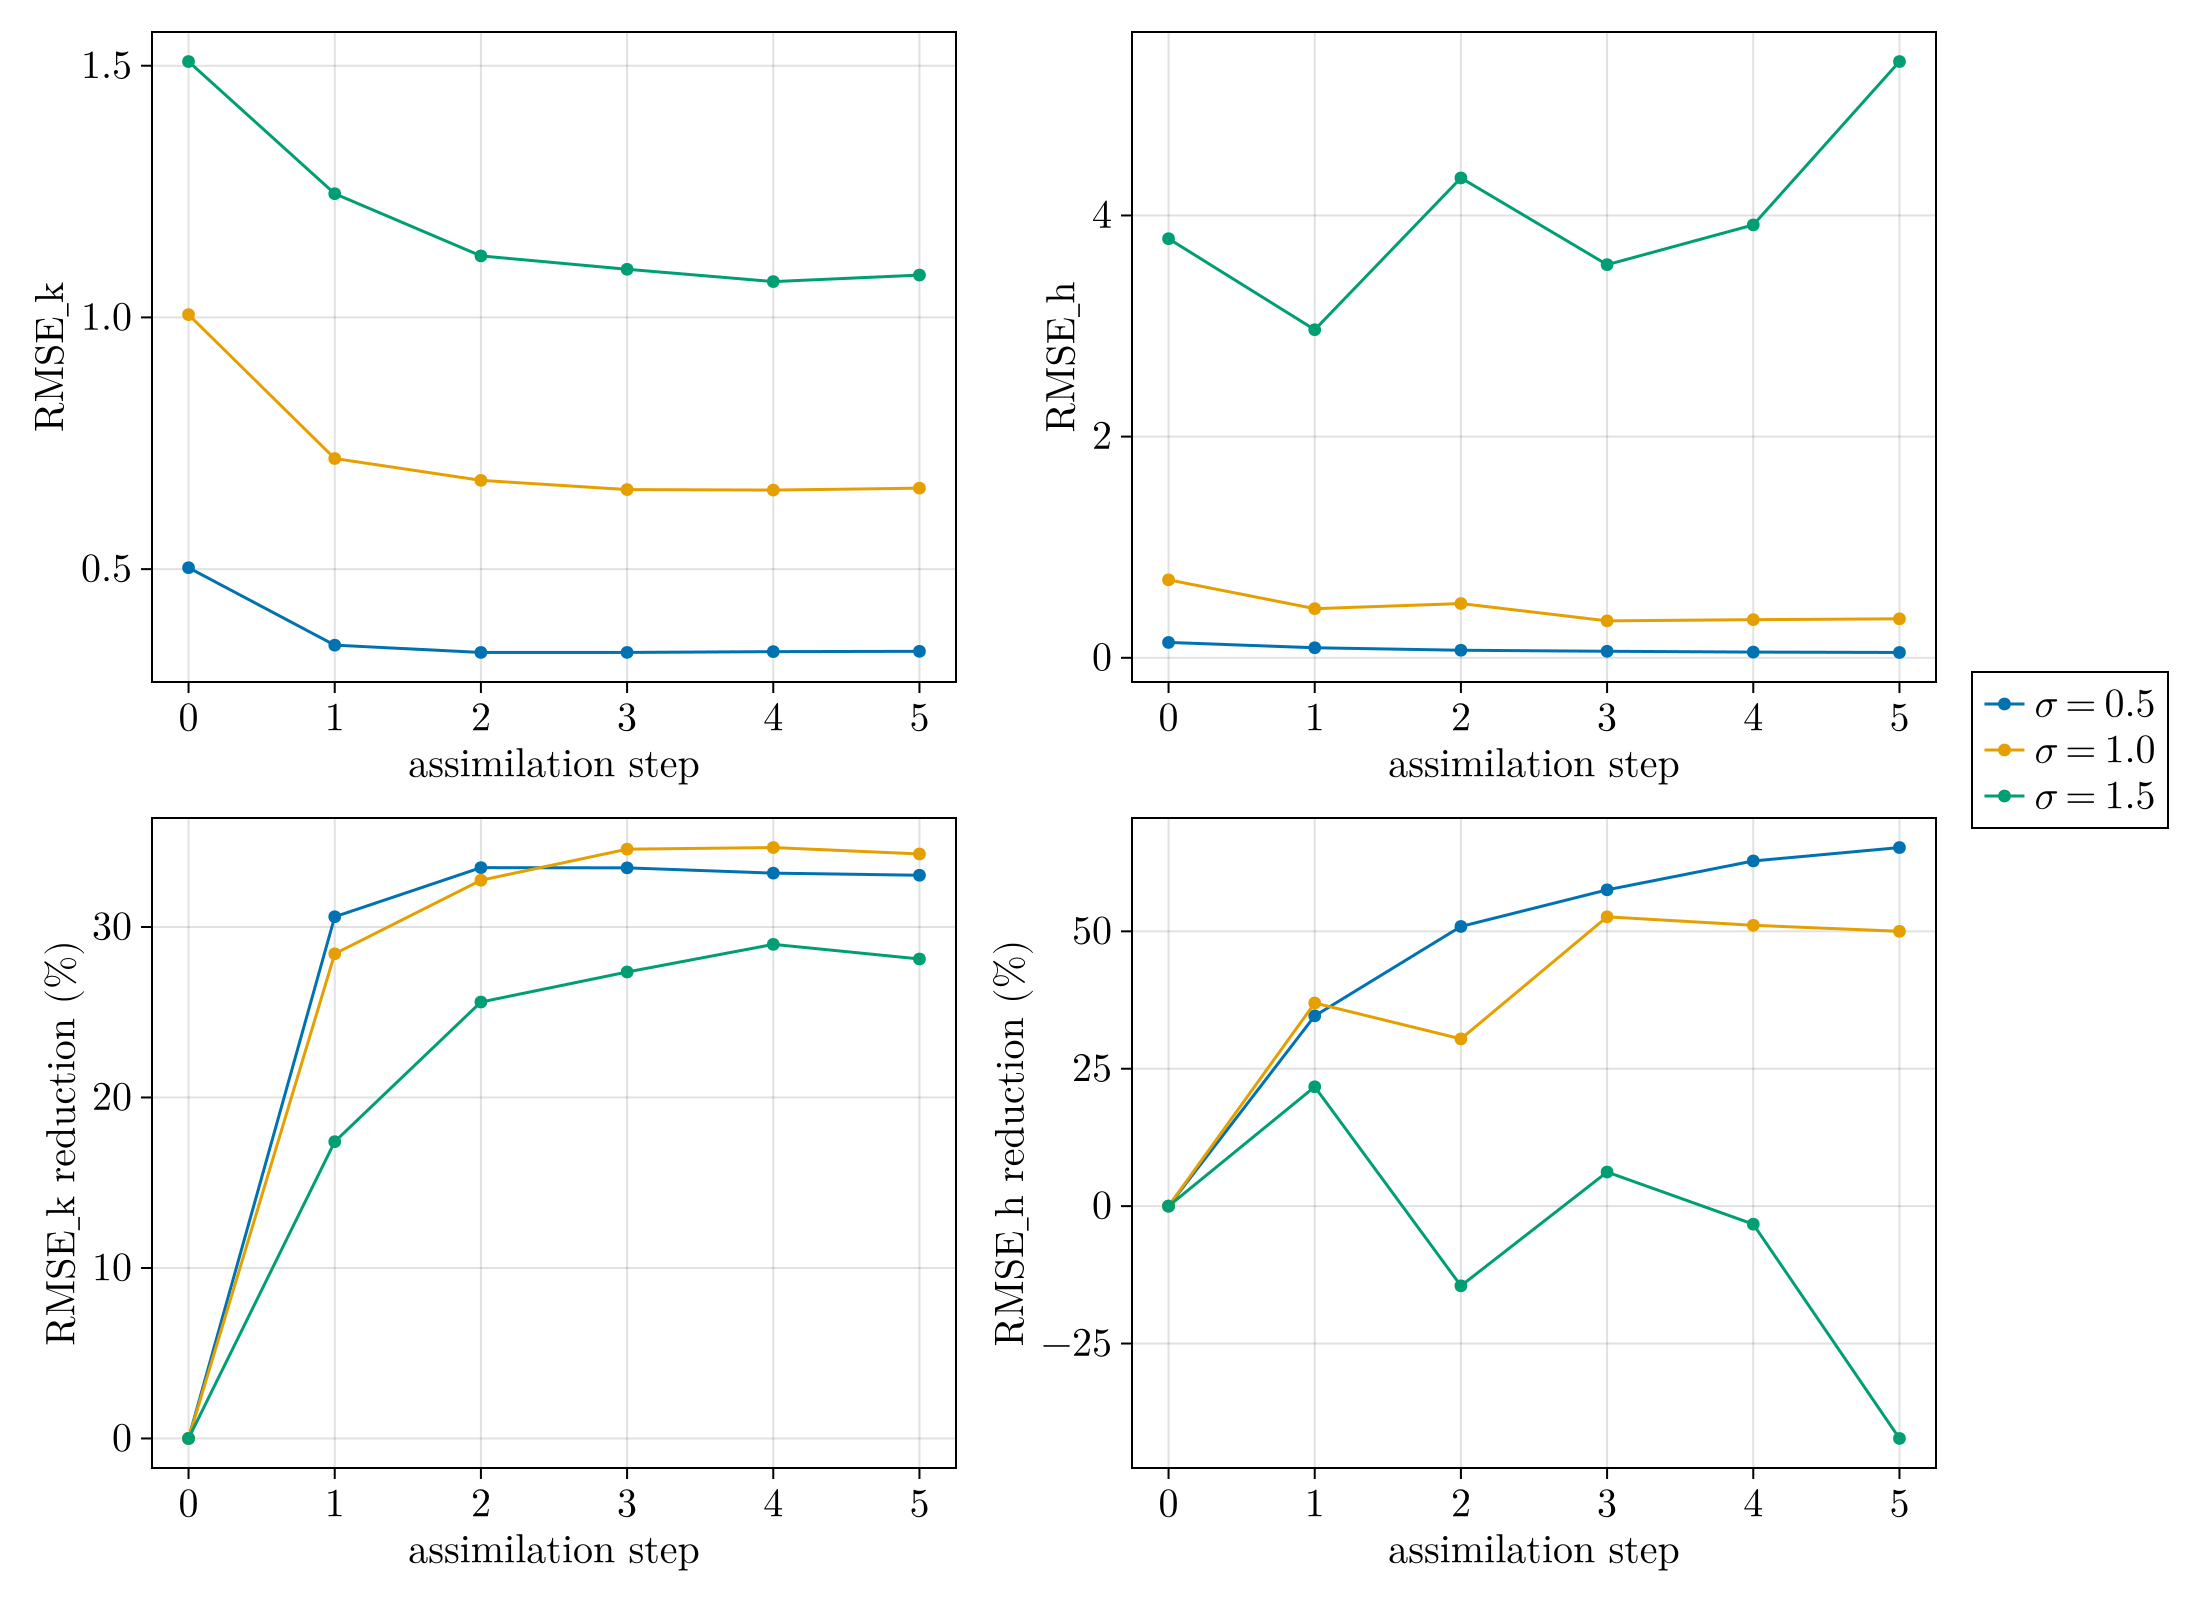

In [15]:
# RMSE and RMSE reduction vs assimilation step, one curve per heterogeneity level
panels = [
    ("RMSE_k", r -> r.rmse_k),
    ("RMSE_h", r -> r.rmse_h),
    ("RMSE_k reduction (%)", r -> reduction(r.rmse_k)),
    ("RMSE_h reduction (%)", r -> reduction(r.rmse_h)),
]
fig3 = Figure(size = (1100, 800))
axs = map(enumerate(panels)) do (n, (ylabel, f))
    ax = Axis(
        fig3[(n - 1) ÷ 2 + 1, (n - 1) % 2 + 1], 
        xticks = steps, 
        xlabel = "assimilation step", 
        ylabel = ylabel
        )
    for r in p2
        scatterlines!(ax, steps, f(r), label = L"\sigma = %$(r.σ)")
    end
    ax
end
Legend(fig3[1:2, 3], axs[1])
fig3

In [16]:
save("figures/hw7-p2-rmse.png", fig3)

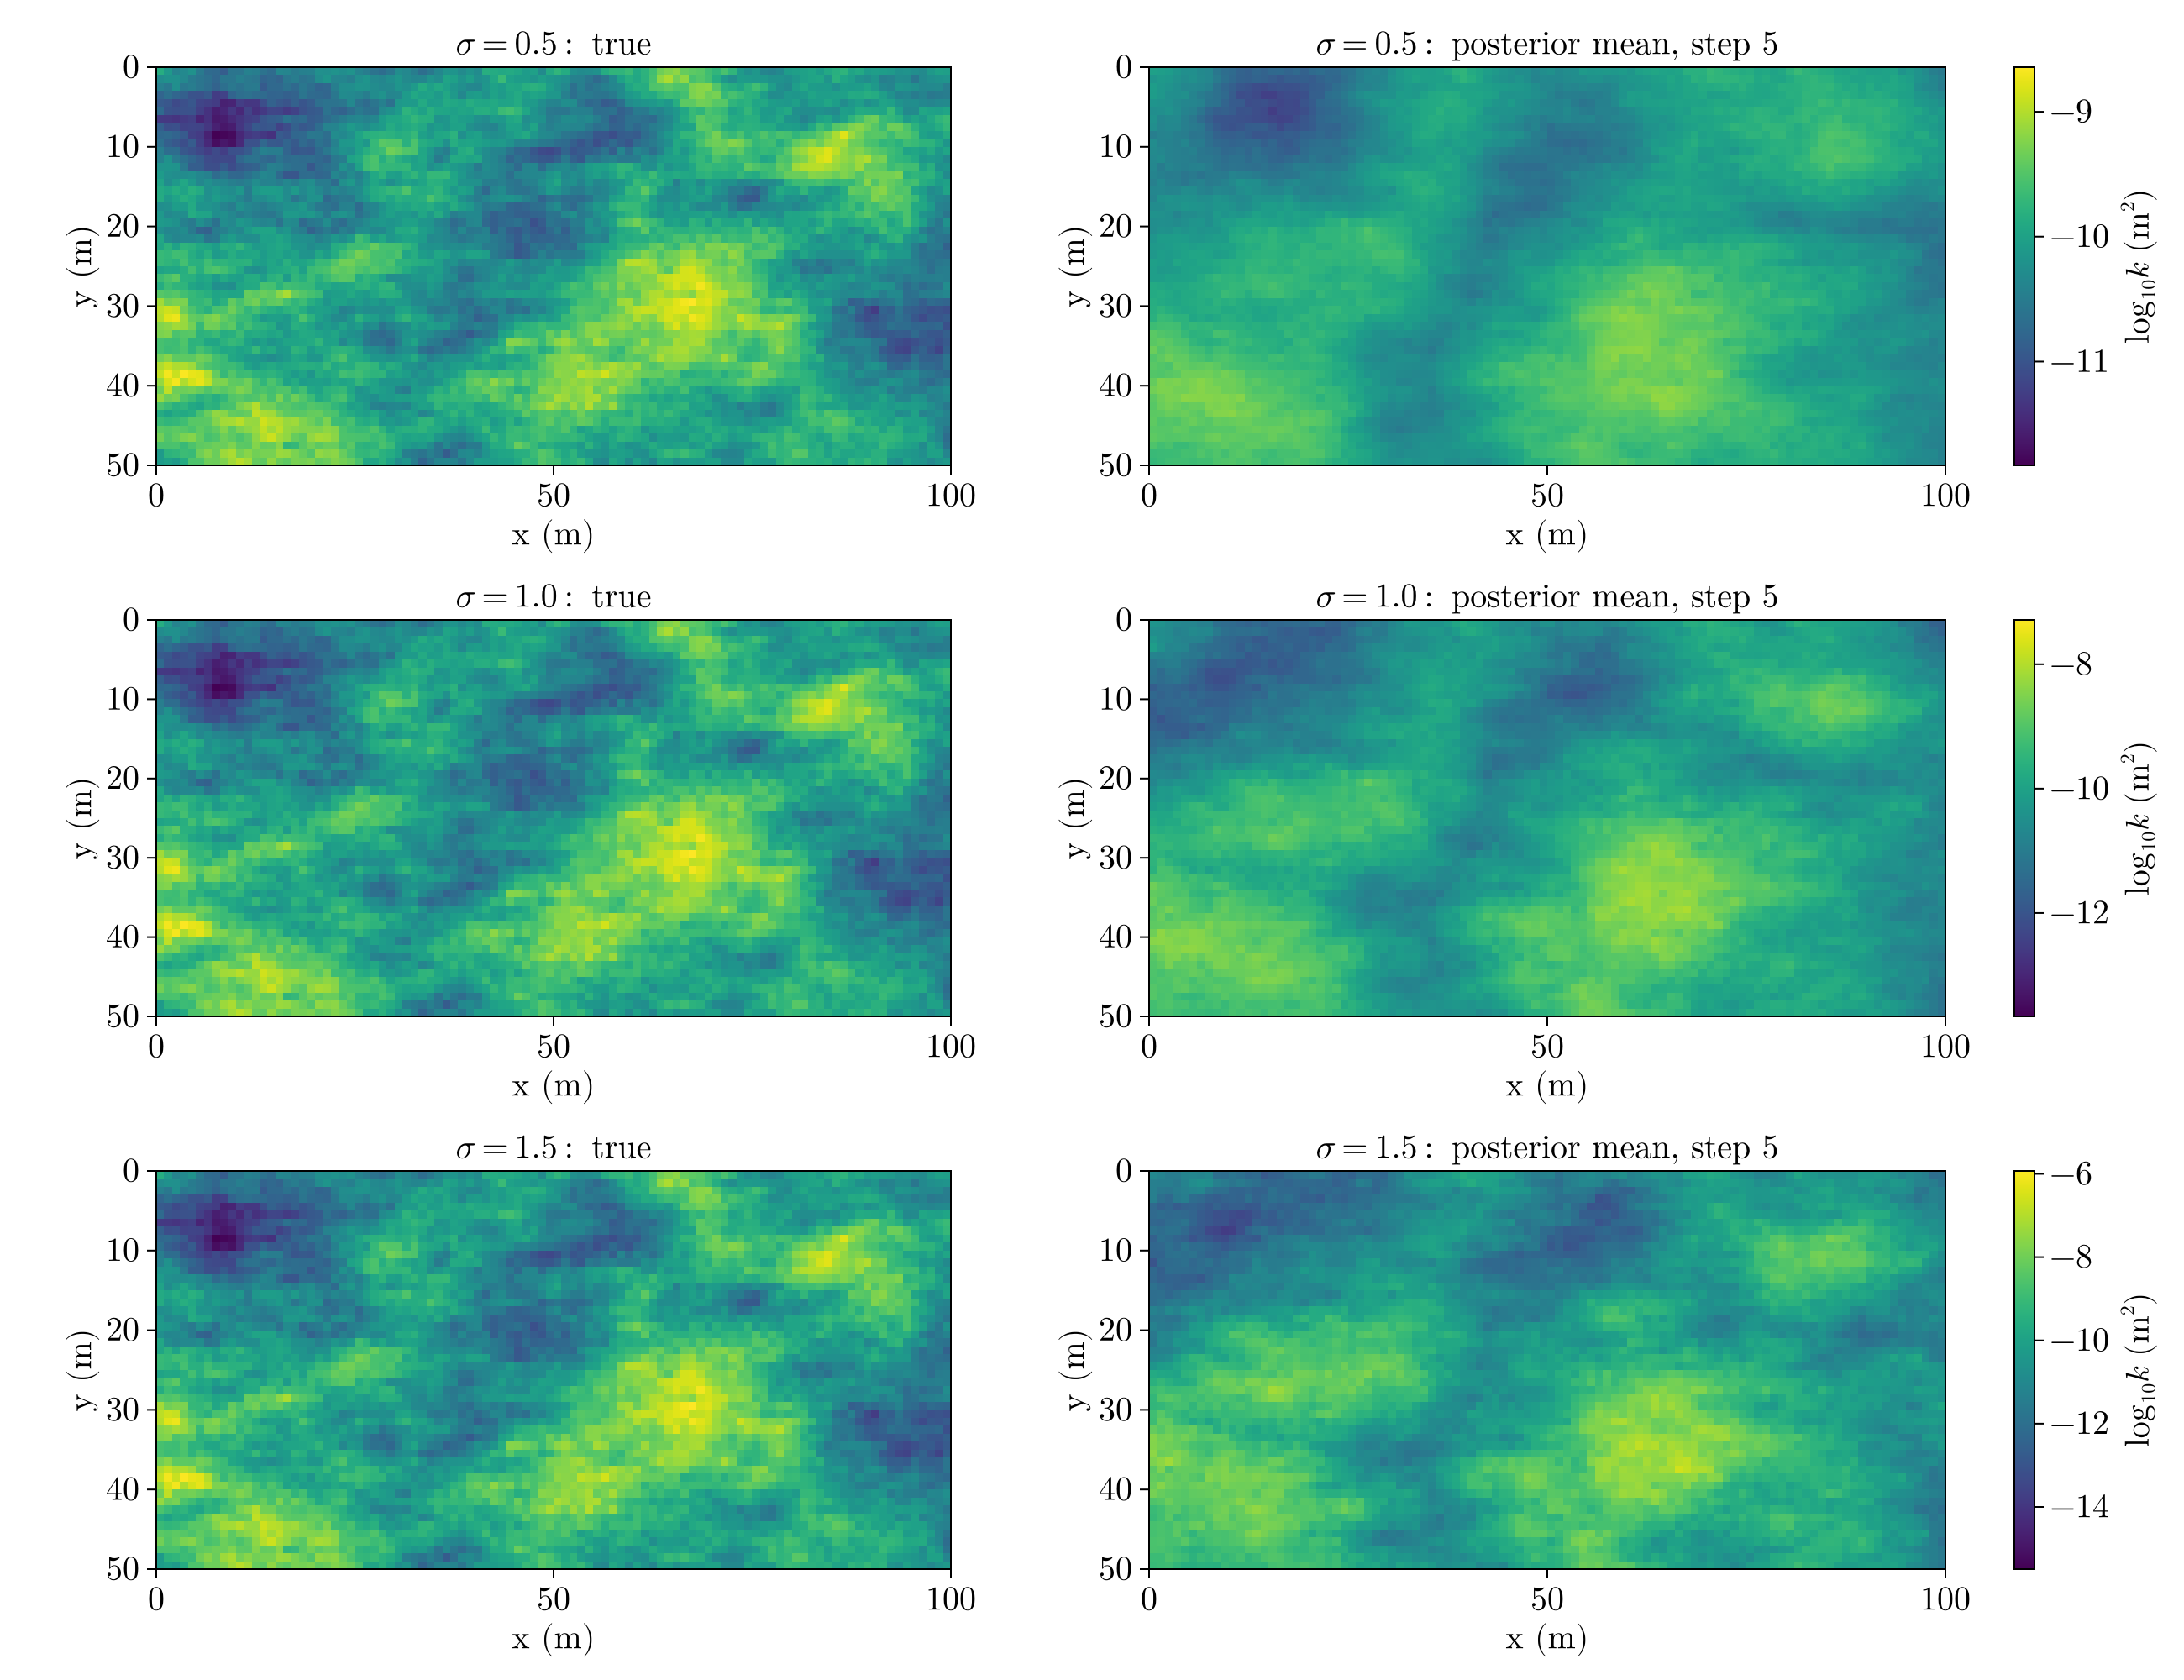

In [17]:
# true vs final posterior ensemble-mean log10(k), same color scale within each row
fig4 = Figure(size = (1300, 1000))
for (n, r) in enumerate(p2)
    krange = extrema(r.xTrue)
    kmap!(fig4[n, 1], r.xTrue, L"\sigma = %$(r.σ):\ \mathrm{true}", krange)
    kmap!(fig4[n, 2], r.xMean_ls[end], L"\sigma = %$(r.σ):\ \mathrm{posterior\ mean,\ step\ %$nUpdate}", krange)
    Colorbar(fig4[n, 3], limits = krange, colormap = :viridis, label = klabel)
end
fig4

In [18]:
save("figures/hw7-p2-maps.png", fig4)

**P2 discussion**

**How does heterogeneity affect absolute RMSE and relative RMSE reduction?**
- Abs(RMSE) goes up with heterogeneity, both before and after the updates. $\mathrm{RMSE}_k$ grows roughly in step with $\sigma_{\log_{10}k}$, since the prior mean is nearly flat and the error is basically the spread of the true field. $\mathrm{RMSE}_h$ grows much faster than $\sigma_{\log_{10}k}$ because head depends on $k$ nonlinearly.
- Relative reduction goes down as heterogeneity goes up. The $\mathrm{RMSE}_k$ reduction is about the same for the two lower levels and smaller for the strongest one. The $\mathrm{RMSE}_h$ reduction drops at each level and turns negative for the strongest one, where the mean head ends up worse than the prior.

**Does stronger heterogeneity always make the inverse problem harder?**

Yes, both RMSEs get bigger. In relative terms not always. Going from the weakest to the middle level barely changes the $\mathrm{RMSE}_k$ reduction; the error just scales with $\sigma_{\log_{10}k}$, and the posterior maps pick up the same large zones at every level. Bigger head contrasts against the same observation error should even make the data more informative. ES-MDA breaks down at the strongest level: $\mathrm{RMSE}_h$ gets worse after the first step even though $\mathrm{RMSE}_k$ still improves. Head is strongly nonlinear in $\log_{10}k$ there, so the linear update pushes a few members to very low $k$ with huge heads, and they dominate the mean head. So it gets harder once the $k$-head relation is too nonlinear for the linear update, not just because the variance is bigger.